In [715]:
%load_ext autoreload
%autoreload 2
import warnings
warnings.filterwarnings('ignore')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [716]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
pd.options.display.max_columns=500
pd.options.display.max_rows=200
pd.options.display.float_format = "{:.3e}".format

In [717]:
path_dados = r"C:\Python - Projects\Aulas WeCogno\Trabalho - Inadimplência\data\raw"

cad = pd.read_parquet(f'{path_dados}/base_cadastral.parquet')
sub = pd.read_parquet(f'{path_dados}/base_submissao.parquet') # por ultimo
hist_emp = pd.read_parquet(f'{path_dados}/historico_emprestimos.parquet')
hist_parc = pd.read_parquet(f'{path_dados}/historico_parcelas.parquet')

In [718]:
cad.head(1) # tem bastante categorica

,id_cliente,sexo,data_nascimento,qtd_filhos,qtd_membros_familia,renda_anual,tipo_renda,ocupacao,tipo_organizacao,nivel_educacao,estado_civil,tipo_moradia,possui_carro,possui_imovel,nota_regiao_cliente,nota_regiao_cliente_cidade
0,100023,Feminino,1994-01-30,1,2.000e+00,"90.000,00",Servidor público,Equipe administrativa,Educação infantil,Ensino superior,Solteiro,Casa ou apartamento,Não,Sim,2,2


In [719]:
sub.head(1) #

,id_cliente,data_solicitacao,dia_semana_solicitacao,hora_solicitacao,tipo_contrato,valor_credito,valor_bem,valor_parcela
0,100023,2025-02-24,segunda-feira,12:28:44,Financiamento de consumo,5.445e+05,4.545e+05,1.756e+04


In [720]:
hist_emp.head(1)

,id_contrato,id_cliente,tipo_contrato,status_contrato,data_decisao,data_liberacao,data_primeiro_vencimento,data_ultimo_vencimento_original,data_ultimo_vencimento,data_encerramento,valor_solicitado,valor_credito,valor_bem,valor_parcela,valor_entrada,percentual_entrada,qtd_parcelas_planejadas,taxa_juros_padrao,taxa_juros_promocional,tipo_pagamento,finalidade_emprestimo,tipo_cliente,faixa_rendimento,tipo_portfolio,tipo_produto,categoria_bem,combinacao_produto,setor_vendedor,canal_venda,area_venda,dia_semana_solicitacao,hora_solicitacao,indicador_ultima_solicitacao_contrato,indicador_ultima_solicitacao_dia,motivo_recusa,acompanhantes_cliente,indicador_seguro_contratado
0,2802425,108129,Empréstimo em dinheiro,Aprovado,2024-08-29,NaN,2024-09-28,2027-08-14,NaN,NaN,6.075e+05,6.797e+05,6.075e+05,2.519e+04,NaN,NaN,3.600e+01,NaN,NaN,Não informado,Não informado,Recorrente,baixa ação,Dinheiro,venda cruzada,Não informado,Dinheiro venda cruzada: low,Não informado,Central de atendimento,-1,quinta-feira,11:05:09,Sim,1,Não se aplica,Desacompanhado,1.000e+00


# Ingestão

## historico_parcelas

In [721]:
hist_parc.head(1)

,id_contrato,id_cliente,versao_parcela,numero_parcela,data_prevista_pagamento,data_real_pagamento,valor_previsto_parcela,valor_pago_parcela
0,1594684,100193,0.000e+00,56,2021-12-21,2021-12-21,3.019e+02,3.019e+02


In [722]:
hist_parc.drop_duplicates()

,id_contrato,id_cliente,versao_parcela,numero_parcela,data_prevista_pagamento,data_real_pagamento,valor_previsto_parcela,valor_pago_parcela
0,1594684,100193,0.000e+00,56,2021-12-21,2021-12-21,3.019e+02,3.019e+02
1,1995642,134723,1.000e+00,38,2021-08-09,2021-08-04,1.295e+04,1.295e+04
2,1720935,176364,1.000e+00,9,2024-03-06,2024-03-04,6.119e+04,6.119e+04
3,1439208,154898,1.000e+00,20,2024-08-11,2024-08-07,8.851e+03,8.851e+03
4,1640082,172575,1.000e+00,4,2022-11-15,2022-11-10,8.720e+03,8.720e+03
...,...,...,...,...,...,...,...,...
1664373,1323172,217502,1.000e+00,2,2022-04-30,2022-07-13,1.145e+04,1.356e+04
1664376,1780171,119721,1.000e+00,7,2020-10-18,2020-09-22,2.563e+03,3.080e+03
1664377,2855181,460177,0.000e+00,4,2023-09-12,2023-09-20,2.422e+03,2.234e+03
1664380,2506179,437996,0.000e+00,55,2020-08-11,2020-08-11,2.250e+03,2.299e+03


In [723]:
hist_parc.data_real_pagamento.isnull().sum()

np.int64(3655)

In [724]:
hist_parc[hist_parc.data_prevista_pagamento== hist_parc.data_prevista_pagamento.max()]

,id_contrato,id_cliente,versao_parcela,numero_parcela,data_prevista_pagamento,data_real_pagamento,valor_previsto_parcela,valor_pago_parcela
351106,1627545,197516,1.000e+00,14,2025-02-22,2025-02-21,6.673e+04,6.673e+04
712116,1746828,280883,0.000e+00,18,2025-02-22,2025-02-22,5.576e+03,5.576e+03
808960,1031863,350738,0.000e+00,39,2025-02-22,2025-02-17,1.125e+04,1.125e+04
840373,1606187,376101,1.000e+00,4,2025-02-22,2025-02-17,6.153e+04,6.153e+04


In [725]:
hist_parc['data_prevista_pagamento'] = pd.to_datetime(hist_parc['data_prevista_pagamento'], format='%Y-%m-%d', errors='coerce')
hist_parc['data_real_pagamento'] = pd.to_datetime(hist_parc['data_real_pagamento'], format='%Y-%m-%d') # não vou preencher por enquanto ! fillna(pd.Timestamp('2025-01-31'))

hist_parc['dias_atraso'] = (hist_parc['data_real_pagamento'] - hist_parc['data_prevista_pagamento']).dt.days.astype('Int64')


In [726]:
## Criando feature de dias_atraso -> checando inadimplência pré-tratamento
hist_parc['t90'] = hist_parc.dias_atraso >= 90 # classico para banco
hist_parc['t60'] = hist_parc.dias_atraso >= 60
hist_parc['t30'] = hist_parc.dias_atraso >= 30
hist_parc['t1'] = hist_parc.dias_atraso >= 1 #mais agressivo - 14,07% é muito. Falência

In [727]:
## Checando inadimplência inicial
hist_parc[['t90', 't60', 't30', 't1']].sum()/len(hist_parc)*100

t90   2.417e-01
t60   6.501e-01
t30   1.502e+00
t1    1.407e+01
dtype: Float64

### Problemas encontrados e soluções

#### 1) `versao_parcela` varia para um mesmo `numero_parcela`, de um determinado contrato de um cliente. 

Decisão: Manter a parcela mais recente (maior valor)

In [728]:
# grp -> agrupar parcelas parciais: soma os valores valor_pago_parcela nas mesmas versoes
grp = hist_parc.groupby(['id_contrato','id_cliente','numero_parcela']).agg(
    versao_parcela = ('versao_parcela', 'max'),
    valor_pago_parcela_tot = ('valor_pago_parcela', 'sum'),
    valor_previsto_parcela = ('valor_previsto_parcela', 'first'),
    dias_atraso_max = ('dias_atraso', 'max')
).reset_index()
grp['deficit'] = grp.valor_previsto_parcela - grp.valor_pago_parcela_tot
grp['deficit_perc'] = grp.deficit/grp.valor_previsto_parcela
grp

,id_contrato,id_cliente,numero_parcela,versao_parcela,valor_pago_parcela_tot,valor_previsto_parcela,dias_atraso_max,deficit,deficit_perc
0,1000003,252457,1,1.000e+00,4.951e+03,4.951e+03,-14,0.000e+00,0.000e+00
1,1000003,252457,2,1.000e+00,4.951e+03,4.951e+03,-17,0.000e+00,0.000e+00
2,1000003,252457,3,1.000e+00,4.951e+03,4.951e+03,-15,0.000e+00,0.000e+00
3,1000013,215520,1,1.000e+00,1.335e+04,1.335e+04,-6,0.000e+00,0.000e+00
4,1000013,215520,2,1.000e+00,1.335e+04,1.335e+04,-6,0.000e+00,0.000e+00
...,...,...,...,...,...,...,...,...,...
1574406,2870412,466247,8,0.000e+00,1.545e+05,1.545e+05,0,0.000e+00,0.000e+00
1574407,2870412,466247,9,0.000e+00,1.545e+05,1.545e+05,0,0.000e+00,0.000e+00
1574408,2870412,466247,10,0.000e+00,3.096e+05,1.545e+05,1,-1.552e+05,-1.005e+00
1574409,2870415,466248,1,1.000e+00,4.912e+02,4.912e+02,0,0.000e+00,0.000e+00


In [729]:
chave = ['id_contrato', 'id_cliente', 'numero_parcela', 'versao_parcela']

parc = grp.merge(hist_parc.drop(columns=['dias_atraso', 'valor_previsto_parcela', 'valor_pago_parcela']) # mantém apenas o último pagamento e dropa as multiplas entradas
                 .sort_values('data_real_pagamento', na_position='first')
                 .drop_duplicates(subset=chave, keep='last'),
          on=chave,
          how='left')

ord_parc = ['id_contrato', 'id_cliente', 'numero_parcela', 'versao_parcela', 'valor_previsto_parcela', 
            'valor_pago_parcela_tot', 'deficit', 'deficit_perc', 'data_prevista_pagamento', 'data_real_pagamento',
            'dias_atraso_max']
parc = parc[ord_parc].sort_values(by=['id_contrato', 'id_cliente', 'numero_parcela','versao_parcela'])

In [730]:
## atraso com máx de dias_atraso daquela parcela
parc['t1'] = parc.dias_atraso_max >= 1
parc['t30'] = parc.dias_atraso_max >= 30
parc['t60'] = parc.dias_atraso_max >= 60
parc['t90'] = parc.dias_atraso_max >= 90 # classico para banco

In [731]:
display(hist_parc[['t90', 't60', 't30', 't1']].sum()/len(hist_parc)*100) # taxas de inadimplência por períodos de atraso de pagamento (nas versões mais atuais)
display(parc[['t90', 't60', 't30', 't1']].sum()/len(parc)*100)

t90   2.417e-01
t60   6.501e-01
t30   1.502e+00
t1    1.407e+01
dtype: Float64

t90   2.513e-01
t60   6.792e-01
t30   1.568e+00
t1    1.450e+01
dtype: Float64

### 2) Como inadimplência varia de acordo com tempo de atraso

In [732]:
tst_dias_atraso = parc.drop(columns=['t90', 't60', 't30', 't1'])

In [733]:
for i in range(1, 181):
    tst_dias_atraso[f't{i}'] = tst_dias_atraso['dias_atraso_max'] >= i


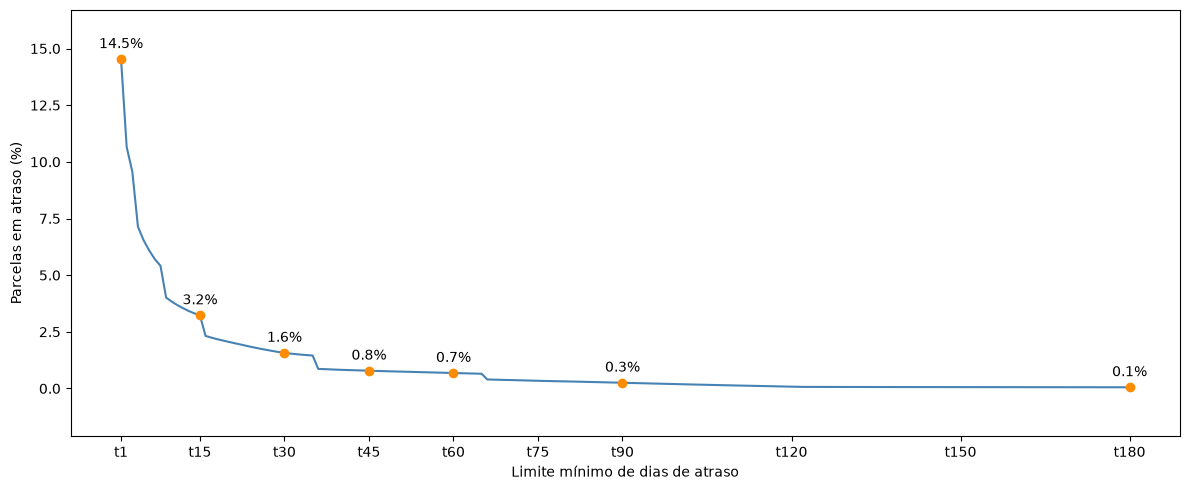

In [734]:

dias = list(range(1, 181))
taxas = tst_dias_atraso[[f"t{dia}" for dia in dias]].mean() * 100
taxas.index = dias

destaques = [1, 15, 30, 45, 60, 90, 180]
mobs = [1, *range(15, 91, 15), *range(120, 181, 30)]

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(dias, taxas, color="steelblue")
ax.scatter(destaques, taxas.loc[destaques], color="darkorange", zorder=3)

for dia in destaques:
    taxa = taxas.loc[dia]
    ax.annotate(
        f"{taxa:.1f}%",
        (dia, taxa),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
    )

ax.set_xticks(mobs, labels=[f"t{dia}" for dia in mobs])
ax.set_xlabel("Limite mínimo de dias de atraso")
ax.set_ylabel("Parcelas em atraso (%)")
ax.margins(y=0.15)
fig.tight_layout()
plt.show()

-> convém manter atraso >= 15 dias como valor mínimo de atraso para inadimplência! (Regra do cotovelo)

### 3) Comparando possíveis cenários de taxa de inadimplência

Inadimplência -> definido como contratos cuja empresa credora não tem mais confiança de que haverá pagamento.

atraso != inadimplência!

3 Condições principais:

   - Deve existir atraso considerável -> definir com base no gráfico anterior
   - deficit > 1 (pelo menos 1 real de débito pendente)
   - deficit_perc > 5% (1 real deve representar ao menos 5% do valor total)

In [735]:
parc.id_contrato.nunique()

122867

## base_cadastral - cad

In [739]:
len(cad)

50600

In [740]:
## criando feats_cad para passar depois no merge -> id_cliente e sexo já serão presentes.
feats_cad = [i for i in cad.columns.drop(["id_cliente", "sexo"])]

In [741]:
print(feats_cad)

['data_nascimento', 'qtd_filhos', 'qtd_membros_familia', 'renda_anual', 'tipo_renda', 'ocupacao', 'tipo_organizacao', 'nivel_educacao', 'estado_civil', 'tipo_moradia', 'possui_carro', 'possui_imovel', 'nota_regiao_cliente', 'nota_regiao_cliente_cidade']


In [742]:
cad.head(1)

,id_cliente,sexo,data_nascimento,qtd_filhos,qtd_membros_familia,renda_anual,tipo_renda,ocupacao,tipo_organizacao,nivel_educacao,estado_civil,tipo_moradia,possui_carro,possui_imovel,nota_regiao_cliente,nota_regiao_cliente_cidade
0,100023,Feminino,1994-01-30,1,2.000e+00,"90.000,00",Servidor público,Equipe administrativa,Educação infantil,Ensino superior,Solteiro,Casa ou apartamento,Não,Sim,2,2


In [743]:
import re
from unicodedata import normalize

# Conversão de texto para float (renda)
def fix_renda(txt):

    rgx = '[\d,]'
    res = ''.join(re.findall(rgx, txt)).replace(',', '.')
    if res == '':
        return '0'
    return res


## arrumando strings: strings -> padronizar lower_case, tirar espaços e acentos


def fix_strings_cat(txt):
    return re.sub(r"[\u0300-\u036f]", "", normalize("NFD", txt.strip().lower()))

In [744]:
from pandas.api.types import is_numeric_dtype
## drop duplicadas (sem informação, não tem como escolher qual é a mais atual -> falta informação de timestamp/versao/data referencia)
## escolhido manter os registros com menor renda, mesmo que esta seja negativa!
cad.duplicated(subset=['id_cliente']).sum()
cad = cad.sort_values(['id_cliente', 'renda_anual']).drop_duplicates(subset=['id_cliente'], keep='first')

# coluna sexo -> dropar:
cad = cad.drop(columns=['sexo'], errors='ignore')

## possui_carro/possui_imovel -> binária. Se nao tiver informação -> assumir 0!
for coluna in ["possui_carro", "possui_imovel"]:
    valores = cad[coluna].map(lambda x: fix_strings_cat(x) if isinstance(x, str) else x,
        na_action="ignore")
    cad[coluna] = valores.replace({"sim": 1, "nao": 0, "nao informado": pd.NA}).astype("Int64").fillna(0)

## data_nascimento -> datetime
cad['data_nascimento'] = pd.to_datetime(cad.data_nascimento, format="%Y-%m-%d", errors="coerce")
cad['data_nascimento'] = cad['data_nascimento'].replace({
    pd.Timestamp("1901-05-20"): pd.NaT,
    pd.Timestamp("2030-01-01"): pd.NaT    
})
filtro = cad['data_nascimento'].isna() | cad['data_nascimento'].gt(pd.Timestamp('2012-01-01'))
cad.loc[filtro, 'data_nascimento'] = cad.loc[~filtro, 'data_nascimento'].median() # idades de 2012 -> transformar para mediana ()

    
## qtd_filhos (int64) >= 0, qtd_membros_familia (int64) >= 1. Assumir valores mínimos se não informado.
cad['qtd_filhos'] = cad['qtd_filhos'].astype('Int64').clip(lower=0).fillna(0)
cad['qtd_membros_familia'] = cad['qtd_membros_familia'].astype('Int64').clip(lower=1).fillna(1)

## renda -> transformar em float e tirar nulos (-> 0)
if not is_numeric_dtype(cad['renda_anual']):
    cad['renda_anual'] = cad.renda_anual.apply(lambda x: fix_renda(x))

cad.renda_anual = cad.renda_anual.fillna(0).astype(float)

## ajustando ['tipo_renda', 'ocupacao', 'tipo_organizacao', 'nivel_educacao', 'estado_civil', 'tipo_moradia']

for column in ['tipo_renda', 'ocupacao', 'tipo_organizacao', 'nivel_educacao', 'estado_civil', 'tipo_moradia']:
    cad[column] = cad[column].fillna("nao informado").apply(lambda x: fix_strings_cat(x))

### Resumo de alterações e checagens



## historico_emprestimos

In [745]:
hist_emp.head(1)

,id_contrato,id_cliente,tipo_contrato,status_contrato,data_decisao,data_liberacao,data_primeiro_vencimento,data_ultimo_vencimento_original,data_ultimo_vencimento,data_encerramento,valor_solicitado,valor_credito,valor_bem,valor_parcela,valor_entrada,percentual_entrada,qtd_parcelas_planejadas,taxa_juros_padrao,taxa_juros_promocional,tipo_pagamento,finalidade_emprestimo,tipo_cliente,faixa_rendimento,tipo_portfolio,tipo_produto,categoria_bem,combinacao_produto,setor_vendedor,canal_venda,area_venda,dia_semana_solicitacao,hora_solicitacao,indicador_ultima_solicitacao_contrato,indicador_ultima_solicitacao_dia,motivo_recusa,acompanhantes_cliente,indicador_seguro_contratado
0,2802425,108129,Empréstimo em dinheiro,Aprovado,2024-08-29,NaN,2024-09-28,2027-08-14,NaN,NaN,6.075e+05,6.797e+05,6.075e+05,2.519e+04,NaN,NaN,3.600e+01,NaN,NaN,Não informado,Não informado,Recorrente,baixa ação,Dinheiro,venda cruzada,Não informado,Dinheiro venda cruzada: low,Não informado,Central de atendimento,-1,quinta-feira,11:05:09,Sim,1,Não se aplica,Desacompanhado,1.000e+00


In [810]:
## feats_emp -> dados presentes em sub

hist_emp['proxy_data_solicitacao'] = pd.to_datetime(hist_emp.data_liberacao.fillna(hist_emp.data_decisao), format="%Y-%m-%d", errors="coerce")

feats_emp = ['valor_solicitado','proxy_data_solicitacao','dia_semana_solicitacao', 'hora_solicitacao', 'tipo_contrato', 'valor_credito', 'valor_bem', 'valor_parcela']

hist_emp_apr = hist_emp[hist_emp.status_contrato=='aprovado']
df_emp = (hist_emp_apr[['id_cliente', 'id_contrato'] + feats_emp]).copy()
df_emp.info()

<class 'pandas.DataFrame'>
Index: 131735 entries, 0 to 211942
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   id_cliente              131735 non-null  int64         
 1   id_contrato             131735 non-null  int64         
 2   valor_solicitado        131735 non-null  float64       
 3   proxy_data_solicitacao  131735 non-null  datetime64[us]
 4   dia_semana_solicitacao  131735 non-null  str           
 5   hora_solicitacao        131735 non-null  object        
 6   tipo_contrato           131735 non-null  str           
 7   valor_credito           131735 non-null  float64       
 8   valor_bem               131735 non-null  float64       
 9   valor_parcela           131734 non-null  float64       
dtypes: datetime64[us](1), float64(4), int64(2), object(1), str(2)
memory usage: 15.1+ MB


In [811]:
from pandas.api.types import is_string_dtype

## limpar dados de colunas str -> sem duplicatas devido à padronização do texto
for i in df_emp.columns:
    if not re.match(r'data_', i) and is_string_dtype(df_emp[i]) and i!='hora_solicitacao':
      df_emp[i] = df_emp[i].replace({np.nan: 'nao informado'}).map(lambda x: fix_strings_cat(x))

## datas: criar duas feats: proxy_data_solicitacao e tempo_contrato_original
df_emp['hora_solicitacao'] = pd.to_datetime(df_emp['hora_solicitacao'], format='%H:%M:%S').dt.time

## valor_bem -> fillna com valor_solicitado
df_emp['valor_bem'] = df_emp["valor_bem"].fillna(df_emp.valor_solicitado)


In [812]:
## 50000 dados de valor_parcela faltantes
df_emp.sort_values(by="valor_parcela", ascending=True)

,id_cliente,id_contrato,valor_solicitado,proxy_data_solicitacao,dia_semana_solicitacao,hora_solicitacao,tipo_contrato,valor_credito,valor_bem,valor_parcela
154673,398289,1256993,0.000e+00,2025-01-28,terca-feira,08:39:30,emprestimo em dinheiro,0.000e+00,0.000e+00,0.000e+00
91935,148571,2612933,5.934e+04,2022-08-23,terca-feira,16:31:05,credito rotativo,4.746e+04,5.934e+04,0.000e+00
141328,357797,1799437,0.000e+00,2024-03-20,quarta-feira,13:17:36,emprestimo em dinheiro,0.000e+00,0.000e+00,0.000e+00
105507,450679,1367870,2.925e+04,2022-07-10,domingo,15:26:14,financiamento de consumo,2.940e+04,2.925e+04,0.000e+00
58673,232222,1760676,0.000e+00,2024-08-27,terca-feira,14:06:01,financiamento de consumo,0.000e+00,0.000e+00,0.000e+00
...,...,...,...,...,...,...,...,...,...,...
194361,459230,2852834,1.660e+06,2021-08-25,terca-feira,17:10:12,credito rotativo,1.739e+06,1.660e+06,4.381e+05
189999,457485,2848472,1.667e+06,2022-07-11,sabado,15:49:15,financiamento de consumo,1.907e+06,1.682e+06,4.586e+05
209467,465263,2867940,1.863e+06,2022-12-19,sexta-feira,08:50:34,credito rotativo,2.000e+06,1.506e+06,4.618e+05
207205,464363,2865678,1.937e+06,2020-10-27,quarta-feira,03:12:24,credito rotativo,2.000e+06,1.937e+06,4.750e+05


In [815]:
df_emp[(df_emp.valor_solicitado==0)&(df_emp.valor_credito==0)]

,id_cliente,id_contrato,valor_solicitado,proxy_data_solicitacao,dia_semana_solicitacao,hora_solicitacao,tipo_contrato,valor_credito,valor_bem,valor_parcela
312,377968,2436131,0.000e+00,2023-11-05,domingo,12:07:02,emprestimo em dinheiro,0.000e+00,0.000e+00,0.000e+00
1126,216292,1618503,0.000e+00,2023-09-04,sabado,18:51:56,financiamento de consumo,0.000e+00,0.000e+00,0.000e+00
1937,376193,2463114,0.000e+00,2024-07-12,sexta-feira,11:33:13,emprestimo em dinheiro,0.000e+00,0.000e+00,0.000e+00
1976,165043,2102381,0.000e+00,2024-07-22,sexta-feira,16:55:20,financiamento de consumo,0.000e+00,0.000e+00,0.000e+00
2140,426338,2701873,0.000e+00,2024-07-25,sexta-feira,14:42:04,credito rotativo,0.000e+00,0.000e+00,0.000e+00
3078,270231,1244555,0.000e+00,2024-10-01,terca-feira,11:12:15,financiamento de consumo,0.000e+00,0.000e+00,0.000e+00
5157,439911,1387753,0.000e+00,2023-09-17,domingo,17:07:06,emprestimo em dinheiro,0.000e+00,0.000e+00,0.000e+00
6064,287167,1877956,0.000e+00,2024-04-24,terca-feira,14:22:39,financiamento de consumo,0.000e+00,0.000e+00,0.000e+00
6768,207377,1672119,0.000e+00,2023-11-18,sabado,11:31:57,emprestimo em dinheiro,0.000e+00,0.000e+00,0.000e+00
7106,171115,2368479,0.000e+00,2024-03-27,quarta-feira,11:08:50,credito rotativo,0.000e+00,0.000e+00,0.000e+00


In [700]:
sub.head(1)

,id_cliente,data_solicitacao,dia_semana_solicitacao,hora_solicitacao,tipo_contrato,valor_credito,valor_bem,valor_parcela
0,100023,2025-02-24,segunda-feira,12:28:44,Financiamento de consumo,5.445e+05,4.545e+05,1.756e+04


In [701]:
## Organizando as colunas -> filtrando apenas as presentes em sub

feats_emp = ['valor_solicitado','proxy_data_solicitacao','dia_semana_solicitacao', 'hora_solicitacao', 'tipo_contrato', 'valor_credito', 'valor_bem', 'valor_parcela']
df_emp = hist_emp[['id_cliente', 'id_contrato'] + feats_emp].copy()
df_emp.info()

<class 'pandas.DataFrame'>
RangeIndex: 211944 entries, 0 to 211943
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   id_cliente              211944 non-null  int64         
 1   id_contrato             211944 non-null  int64         
 2   valor_solicitado        211944 non-null  float64       
 3   proxy_data_solicitacao  211944 non-null  datetime64[us]
 4   dia_semana_solicitacao  211944 non-null  str           
 5   hora_solicitacao        211944 non-null  str           
 6   tipo_contrato           211944 non-null  str           
 7   valor_credito           211944 non-null  float64       
 8   valor_bem               211944 non-null  float64       
 9   valor_parcela           160679 non-null  float64       
dtypes: datetime64[us](1), float64(4), int64(2), str(3)
memory usage: 24.2 MB


In [702]:
# Checar colunas retiradas
hist_emp.columns[~hist_emp.columns.isin(df_emp.columns)]

Index(['status_contrato', 'data_decisao', 'data_liberacao',
       'data_primeiro_vencimento', 'data_ultimo_vencimento_original',
       'data_ultimo_vencimento', 'data_encerramento', 'valor_entrada',
       'percentual_entrada', 'qtd_parcelas_planejadas', 'taxa_juros_padrao',
       'taxa_juros_promocional', 'tipo_pagamento', 'finalidade_emprestimo',
       'tipo_cliente', 'faixa_rendimento', 'tipo_portfolio', 'tipo_produto',
       'categoria_bem', 'combinacao_produto', 'setor_vendedor', 'canal_venda',
       'area_venda', 'indicador_ultima_solicitacao_contrato',
       'indicador_ultima_solicitacao_dia', 'motivo_recusa',
       'acompanhantes_cliente', 'indicador_seguro_contratado',
       'indicador_valor_entrada_ausente'],
      dtype='str')

## base_submissao -> mesmas alterações que historico_emprestimos (mas apenas nas colunas presentes por enquanto)



In [703]:
sub.head(1)

,id_cliente,data_solicitacao,dia_semana_solicitacao,hora_solicitacao,tipo_contrato,valor_credito,valor_bem,valor_parcela
0,100023,2025-02-24,segunda-feira,12:28:44,Financiamento de consumo,5.445e+05,4.545e+05,1.756e+04


In [704]:
print(sub.data_solicitacao.min())
print(df_emp.proxy_data_solicitacao.max())

2025-02-04
2025-03-09 00:00:00


In [705]:
display(df_emp[df_emp.proxy_data_solicitacao>=pd.Timestamp("2025-02-04")])
display(df_emp)
display(sub.sort_values(by='data_solicitacao'))

,id_cliente,id_contrato,valor_solicitado,proxy_data_solicitacao,dia_semana_solicitacao,hora_solicitacao,tipo_contrato,valor_credito,valor_bem,valor_parcela
314,236586,1342469,0.000e+00,2025-02-05,quarta-feira,12:14:11,emprestimo em dinheiro,0.000e+00,0.000e+00,NaN
327,181013,2265572,0.000e+00,2025-02-07,sexta-feira,09:02:01,emprestimo em dinheiro,0.000e+00,0.000e+00,NaN
329,143624,1919179,2.603e+05,2025-02-18,terca-feira,11:33:34,financiamento de consumo,2.603e+05,2.603e+05,1.387e+04
587,454606,2802541,0.000e+00,2025-02-14,sexta-feira,13:05:15,emprestimo em dinheiro,0.000e+00,0.000e+00,NaN
605,340367,1482712,0.000e+00,2025-02-13,quinta-feira,13:32:46,emprestimo em dinheiro,0.000e+00,0.000e+00,NaN
...,...,...,...,...,...,...,...,...,...,...
208874,465039,2867347,1.480e+04,2025-02-10,quinta-feira,09:11:58,emprestimo em dinheiro,1.499e+04,1.480e+04,NaN
209526,465291,2867999,5.491e+05,2025-02-17,sexta-feira,13:46:15,financiamento de consumo,6.176e+05,6.329e+05,7.374e+04
210836,465790,2869309,1.008e+05,2025-02-04,quarta-feira,07:50:20,credito rotativo,1.029e+05,9.993e+04,NaN
211166,465930,2869639,1.033e+05,2025-03-04,domingo,17:24:08,emprestimo em dinheiro,1.192e+05,1.033e+05,NaN


,id_cliente,id_contrato,valor_solicitado,proxy_data_solicitacao,dia_semana_solicitacao,hora_solicitacao,tipo_contrato,valor_credito,valor_bem,valor_parcela
0,108129,2802425,6.075e+05,2024-08-29,quinta-feira,11:05:09,emprestimo em dinheiro,6.797e+05,6.075e+05,2.519e+04
1,258628,2330894,1.485e+05,2022-10-11,terca-feira,15:46:56,credito rotativo,1.744e+05,1.485e+05,1.217e+04
2,267782,1182516,4.050e+05,2023-04-08,sabado,04:39:38,credito rotativo,4.518e+05,4.050e+05,2.036e+04
3,275707,1543131,2.295e+05,2024-02-08,quinta-feira,08:26:26,credito rotativo,2.419e+05,2.295e+05,2.262e+04
4,299391,2261993,0.000e+00,2024-09-06,sexta-feira,13:25:16,emprestimo em dinheiro,0.000e+00,0.000e+00,NaN
...,...,...,...,...,...,...,...,...,...,...
211939,466247,2870412,8.950e+05,2022-01-21,sexta-feira,14:37:57,emprestimo em dinheiro,1.041e+06,8.379e+05,1.545e+05
211940,466247,2870413,4.313e+04,2024-11-25,domingo,15:26:09,emprestimo em dinheiro,4.372e+04,5.237e+04,NaN
211941,466248,2870414,1.067e+06,2024-08-08,terca-feira,14:26:50,financiamento de consumo,1.034e+06,8.799e+05,NaN
211942,466248,2870415,5.067e+03,2024-11-17,domingo,15:47:45,emprestimo em dinheiro,5.000e+03,3.895e+03,4.912e+02


,id_cliente,data_solicitacao,dia_semana_solicitacao,hora_solicitacao,tipo_contrato,valor_credito,valor_bem,valor_parcela
9,100165,2025-02-04,terça-feira,16:46:10,Crédito rotativo,1.294e+06,1.130e+06,3.557e+04
18,100265,2025-02-04,terça-feira,15:29:01,Crédito rotativo,7.240e+05,5.850e+05,3.496e+04
70,100828,2025-02-04,terça-feira,10:14:59,Empréstimo em dinheiro,4.500e+05,4.500e+05,4.788e+04
76,100890,2025-02-04,terça-feira,15:36:11,Financiamento de consumo,5.538e+05,4.950e+05,2.209e+04
82,100927,2025-02-04,terça-feira,08:28:24,Financiamento de consumo,1.350e+06,1.350e+06,5.883e+04
...,...,...,...,...,...,...,...,...
46831,463080,24/02/2025,quarta-feira,10:50:40,Empréstimo em dinheiro,3.030e+05,3.010e+05,6.383e+03
47537,463786,24/02/2025,terça-feira,08:24:52,Financiamento de consumo,2.525e+05,2.825e+05,1.856e+04
47752,464001,24/02/2025,segunda-feira,11:59:01,Financiamento de consumo,3.215e+05,3.120e+05,1.086e+04
48985,465234,24/02/2025,quarta-feira,09:28:39,Empréstimo em dinheiro,1.955e+05,NaN,2.388e+04


In [785]:
## Arrumando datas de solicitacao inválidas -> considerar primeira semana como referência com base no dia_semana

sub.loc[sub['data_solicitacao'].eq('2025-13-01'), 'data_solicitacao'] = (
    sub['dia_semana_solicitacao'].map({
        'segunda-feira': '2025-02-03',
        'terça-feira': '2025-02-04',
        'quarta-feira': '2025-02-05',
        'quinta-feira': '2025-02-06',
        'sexta-feira': '2025-02-07',
        'sábado': '2025-02-08',
        'domingo': '2025-02-09',
    })
)
sub['data_solicitacao'] = pd.to_datetime(sub['data_solicitacao'], format='mixed')
sub.sort_values('data_solicitacao')

## dia_semana -> convertido de acordo com a data (corretamente)
sub.dia_semana_solicitacao = sub.data_solicitacao.dt.day_name(locale='Portuguese_Brazil.1252').map(lambda x: fix_strings_cat(x))

## hora -> invalidas para validas com indicador

hora = pd.to_datetime(sub['hora_solicitacao'], format='%H:%M:%S', errors='coerce')

# se o valor da coluna original nao for nulo mas a conversao levar à NaT, indicar True(1)
sub['indicador_hora_invalida'] = (sub['hora_solicitacao'].notna() & hora.isna()).astype('int8')
sub['hora_solicitacao'] = hora.dt.time


# tipo contrato -> fix str
sub.tipo_contrato = sub.tipo_contrato.map(lambda x: fix_strings_cat(x))

sub.valor_bem = sub.valor_bem.fillna(sub.valor_credito)


## valor parcela -> marcar valores ausentes e imputar utilizando uma proporção dos demais contratos
sub['indicador_valor_parcela_ausente'] = (sub['valor_parcela'].isna() | sub['valor_parcela'].eq(0)).astype('int8')


## valor_parcela -> será imputado com base na mediana de parcelas 
proporcao = (sub['valor_parcela'].where(sub['valor_parcela'].gt(0))/ sub['valor_credito'])
mediana_por_tipo = proporcao.groupby(sub['tipo_contrato']).median().round(4)
sub['valor_parcela'] = sub['valor_parcela'].replace({0:np.nan}) \
    .fillna(sub['valor_credito'] * sub['tipo_contrato'].map(mediana_por_tipo))

## qtd_parcelas_planejadas
sub['qtd_parcelas_planejadas'] = np.ceil(sub['valor_credito'] / sub['valor_parcela'])

In [792]:
sub.iloc[22077]

id_cliente                                         326982
data_solicitacao                      2025-02-24 00:00:00
dia_semana_solicitacao                      segunda-feira
hora_solicitacao                                 17:19:48
tipo_contrato                      emprestimo em dinheiro
valor_credito                                   2.700e+07
valor_bem                                       2.700e+05
valor_parcela                                   7.119e+03
indicador_hora_invalida                                 0
indicador_valor_parcela_ausente                         0
qtd_parcelas_planejadas                              3793
Name: 22077, dtype: object

In [791]:
sub[['id_cliente', 'qtd_parcelas_planejadas']].sort_values(by="qtd_parcelas_planejadas", ascending=False)

,id_cliente,qtd_parcelas_planejadas
22077,326982,3793
47232,463481,3435
14118,245998,3409
35252,144753,3212
43755,460004,3196
...,...,...
41805,458054,5
41771,458020,5
44719,460968,5
41746,457995,5


In [793]:
sub.info()

<class 'pandas.DataFrame'>
RangeIndex: 50400 entries, 0 to 50399
Data columns (total 11 columns):
 #   Column                           Non-Null Count  Dtype         
---  ------                           --------------  -----         
 0   id_cliente                       50400 non-null  int64         
 1   data_solicitacao                 50400 non-null  datetime64[us]
 2   dia_semana_solicitacao           50400 non-null  str           
 3   hora_solicitacao                 50300 non-null  object        
 4   tipo_contrato                    50400 non-null  str           
 5   valor_credito                    50400 non-null  float64       
 6   valor_bem                        50400 non-null  float64       
 7   valor_parcela                    50400 non-null  object        
 8   indicador_hora_invalida          50400 non-null  int8          
 9   indicador_valor_parcela_ausente  50400 non-null  int8          
 10  qtd_parcelas_planejadas          50400 non-null  object        
dtype

In [710]:
sub[sub.valor_parcela.isnull()]

,id_cliente,data_solicitacao,dia_semana_solicitacao,hora_solicitacao,tipo_contrato,valor_credito,valor_bem,valor_parcela
13868,243648,2025-02-15,sábado,12:04:11,Crédito rotativo,9.291e+05,7.200e+05,NaN
25574,364022,2025-02-12,quarta-feira,11:06:12,Financiamento de consumo,6.281e+05,4.995e+05,NaN
27125,379997,2025-02-05,quarta-feira,15:48:40,Empréstimo em dinheiro,1.483e+06,1.354e+06,NaN
37509,289463,2025-02-14,sexta-feira,18:37:18,Financiamento de consumo,7.819e+05,6.750e+05,NaN
50348,364022,2025-02-12,quarta-feira,18:45:54,Financiamento de consumo,6.344e+05,4.995e+05,NaN


In [707]:
sub.info()

<class 'pandas.DataFrame'>
RangeIndex: 50400 entries, 0 to 50399
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id_cliente              50400 non-null  int64  
 1   data_solicitacao        50400 non-null  str    
 2   dia_semana_solicitacao  50400 non-null  str    
 3   hora_solicitacao        50400 non-null  str    
 4   tipo_contrato           50400 non-null  str    
 5   valor_credito           50400 non-null  float64
 6   valor_bem               47940 non-null  float64
 7   valor_parcela           50395 non-null  float64
dtypes: float64(3), int64(1), str(4)
memory usage: 5.5 MB


Pode ferir temporalmente!

-> Precisa garantir que os contratos só olhem para trás historicamente!

Text(0, 0.5, 'Quantidade de contratos')

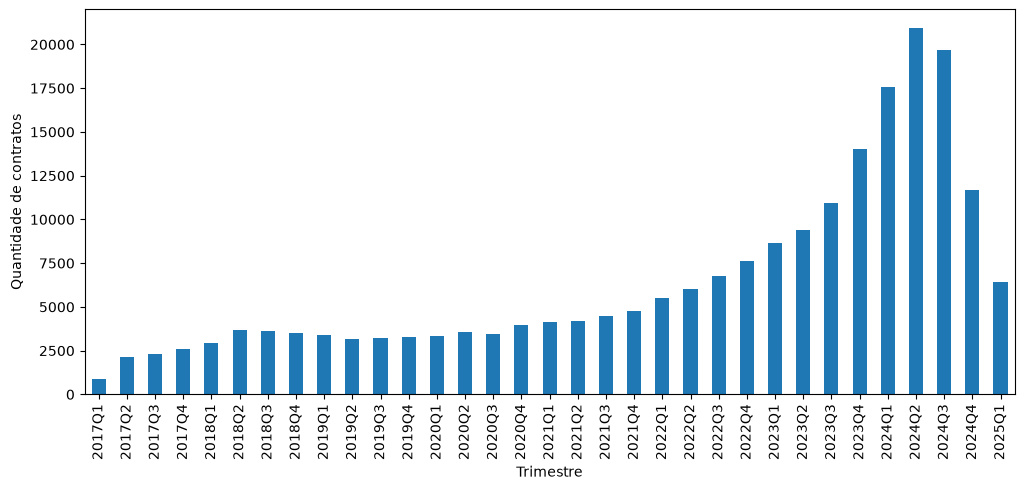

In [370]:
tri = (
    hist_emp.groupby(pd.Grouper(key="proxy_data_solicitacao", freq="QS"))
    ["id_contrato"]
    .count()
    .rename("contratos por semestre")
    .reset_index()
)
datas = tri["proxy_data_solicitacao"]

tri["proxy_data_solicitacao"] = (
    datas.dt.year.astype(str) + "Q" + datas.dt.quarter.astype(str)
)


ax = tri.plot(
    kind="bar",
    x="proxy_data_solicitacao",
    y="contratos por semestre",
    rot=90,
    legend=False,
    figsize=(12,5)
)

ax.set_xlabel("Trimestre")
ax.set_ylabel("Quantidade de contratos")

# Target + Merge e Variáveis históricas

### Target

Condições de inadimplência: 

- Atraso confirmado:
    Atraso em qualquer parcela maior que limite -> OVER
    Somatório dos atrasos das parcelas individuais maior que limite -> EVER

    - t1

    - t15

    - t30

    - t60

    - t90

- Há um deficit considerável em atraso! (há um certo valor de deficit em parcelas com t>1 dia)

    Arbitrando inicialmente valores (checar se faz sentido)

        Condição deficit 1 (dividas baixas porém representam uma porcentagem significativa)

            - 5 > deficit > 0.5

            - deficit_perc > 0.05 

        Condição deficit 2 (dividas maiores)

            - deficit >= 5


Possiveis Targets -> Checar novamente possibilidades de valor e condicionais!

- OVER30
- OVER60
- OVER90
- OVER30 MOB3 -> Atraso >= 30 dias em janela de 3 meses após a data de vencimento da parcela
- OVER90 MOB6 -> Atraso >= 90 dias em janela de 6 meses após a data de vencimento da parcela
- EVER30 -> Somatório de todas os atrasos >= 30 (apenas os positivos?) -> Checar -> neste caso é mais conservador que over30! 
- EVER90 -> Somatório de todas os atrasos >= 90



In [314]:
parc.head(1)

,id_contrato,id_cliente,numero_parcela,versao_parcela,valor_previsto_parcela,valor_pago_parcela_tot,deficit,deficit_perc,data_prevista_pagamento,data_real_pagamento,dias_atraso_max,t1,t30,t60,t90
0,1000003,252457,1,1.000e+00,4.951e+03,4.951e+03,0.000e+00,0.000e+00,2024-11-19,2024-11-05,-14,False,False,False,False


In [826]:
# Targets: OVER: 30, 60, 90 


cond_def = (((parc.deficit>0.5)&(parc.deficit<=5))|(parc.deficit>5))&(parc.t1)

c_30 = parc.t30
c_60 = parc.t60
c_90 = parc.t90

parc['target_over30'] = (cond_def)&(c_30)
parc['target_over60'] = (cond_def)&(c_60)
parc['target_over90'] = (cond_def)&(c_90)
parc[parc.dias_atraso_max>=30]

,id_contrato,id_cliente,numero_parcela,versao_parcela,valor_previsto_parcela,valor_pago_parcela_tot,deficit,deficit_perc,data_prevista_pagamento,data_real_pagamento,dias_atraso_max,t1,t30,t60,t90,target_over30,target_over60,target_over90
364,1000310,328828,9,1.000e+00,5.297e+03,1.187e+04,-6.574e+03,-1.241e+00,2024-03-08,2024-07-05,119,True,True,True,True,False,False,False
420,1000338,277319,24,1.000e+00,8.544e+03,1.022e+04,-1.681e+03,-1.968e-01,2022-08-26,2022-12-13,109,True,True,True,True,False,False,False
631,1000542,193701,11,1.000e+00,2.924e+04,3.151e+04,-2.277e+03,-7.789e-02,2023-07-14,2023-08-14,31,True,True,False,False,False,False,False
640,1000545,423379,2,1.000e+00,1.079e+04,1.413e+04,-3.335e+03,-3.090e-01,2024-01-05,2024-03-12,67,True,True,True,False,False,False,False
787,1000669,380192,8,1.000e+00,2.805e+03,2.805e+03,0.000e+00,0.000e+00,2020-12-27,2021-02-08,43,True,True,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1574213,2870390,466239,7,0.000e+00,2.108e+03,2.477e+03,-3.682e+02,-1.747e-01,2022-01-27,2022-04-02,65,True,True,True,False,False,False,False
1574231,2870394,466240,13,0.000e+00,1.650e+02,1.795e+02,-1.451e+01,-8.793e-02,2020-05-03,2020-06-07,35,True,True,False,False,False,False,False
1574306,2870403,466244,16,1.000e+00,1.967e+02,2.117e+02,-1.493e+01,-7.589e-02,2021-07-04,2021-08-08,35,True,True,False,False,False,False,False
1574307,2870403,466244,17,1.000e+00,1.967e+02,2.241e+02,-2.733e+01,-1.389e-01,2021-08-03,2021-09-07,35,True,True,False,False,False,False,False


In [ ]:

target_over30 = parc.groupby(['id_contrato', 'id_cliente'], as_index=False).agg(target_over30=('target_over30', 'max'))
target_over60 = parc.groupby(['id_contrato', 'id_cliente'], as_index=False).agg(target_over60=('target_over60', 'max'))
target_over90 = parc.groupby(['id_contrato', 'id_cliente'], as_index=False).agg(target_over90=('target_over90', 'max'))

In [322]:
target_contrato

,id_contrato,id_cliente,target
0,1000003,252457,False
1,1000013,215520,False
2,1000019,176905,False
3,1000053,399400,False
4,1000056,248219,False
...,...,...,...
122862,2870408,466246,False
122863,2870410,466247,False
122864,2870411,466247,False
122865,2870412,466247,False


In [325]:
dftr = df_emp.copy()
dftr = dftr.merge(cad[['id_cliente'] + feats_cad], on='id_cliente', how='left').sort_values(by='id_contrato')
dftr


,id_cliente,id_contrato,valor_solicitado,valor_credito,valor_bem,valor_parcela,valor_entrada,tipo_contrato,indicador_ultima_solicitacao_contrato,indicador_ultima_solicitacao_dia,indicador_seguro_contratado,indicador_ultima_solicitacao_contrato,indicador_ultima_solicitacao_dia,indicador_seguro_contratado,qtd_parcelas_planejadas,proxy_data_solicitacao,hora_solicitacao,tipo_contrato,status_contrato,tipo_pagamento,finalidade_emprestimo,tipo_cliente,faixa_rendimento,tipo_portfolio,tipo_produto,categoria_bem,combinacao_produto,setor_vendedor,canal_venda,area_venda,dia_semana_solicitacao,motivo_recusa,acompanhantes_cliente,data_nascimento,qtd_filhos,qtd_membros_familia,renda_anual,tipo_renda,ocupacao,tipo_organizacao,nivel_educacao,estado_civil,tipo_moradia,possui_carro,possui_imovel,nota_regiao_cliente,nota_regiao_cliente_cidade
168155,252457,1000003,4.706e+04,5.264e+04,4.706e+04,4.951e+03,4.275e+00,financiamento de consumo,1,1,1,1,1,1,1.200e+01,2024-10-20,13:08:12,financiamento de consumo,aprovado,dinheiro pelo banco,nao se aplica,reativado,baixa acao,ponto de venda,nao informado,audio e video,ponto de venda casa sem juros,eletronicos de consumo,rede nacional,1103,domingo,nao se aplica,desacompanhado,1986-02-16,1,3,1.575e+05,associado comercial,equipe de vendas,educacao infantil,ensino medio,casado,casa ou apartamento,0,0,2,2
81698,215520,1000013,1.350e+05,1.335e+05,1.350e+05,1.335e+04,1.350e+04,emprestimo em dinheiro,1,1,0,1,1,0,1.200e+01,2021-04-22,18:17:39,emprestimo em dinheiro,aprovado,dinheiro pelo banco,nao se aplica,novo,media,ponto de venda,nao informado,computadores,ponto de venda casa com juros,eletronicos de consumo,regional ou local,121,quinta-feira,nao se aplica,familia,2002-03-21,0,1,9.000e+04,associado comercial,equipe de vendas,entidade empresarial tipo 3,ensino medio,solteiro,casa ou apartamento,0,0,2,2
156682,176905,1000019,6.025e+04,5.137e+04,6.025e+04,6.072e+03,1.350e+04,financiamento de consumo,1,1,0,1,1,0,1.200e+01,2018-09-20,12:18:02,financiamento de consumo,aprovado,dinheiro pelo banco,nao se aplica,recorrente,alta,ponto de venda,nao informado,celular,ponto de venda celular com juros,conectividade,rede nacional,62,quinta-feira,nao se aplica,desacompanhado,1980-09-23,0,2,1.350e+05,assalariado,operarios,transporte tipo 2,ensino medio,uniao estavel,mora com os pais,1,0,3,3
37798,399400,1000053,3.568e+04,2.989e+04,3.568e+04,5.707e+03,7.200e+03,financiamento de consumo,1,1,0,1,1,0,6.000e+00,2021-03-12,15:02:06,financiamento de consumo,aprovado,dinheiro pelo banco,nao se aplica,recorrente,media,ponto de venda,nao informado,foto e cinema,ponto de venda casa com juros,eletronicos de consumo,loja fisica,129,sexta-feira,nao se aplica,desacompanhado,1997-11-12,0,1,1.800e+05,assalariado,garcons e atendentes de bar,entidade empresarial tipo 3,ensino medio,solteiro,casa ou apartamento,1,1,2,2
90082,248219,1000056,2.358e+04,2.567e+04,2.358e+04,3.750e+03,2.340e+03,credito rotativo,1,1,0,1,1,0,1.000e+01,2021-10-30,12:13:18,credito rotativo,aprovado,dinheiro pelo banco,nao se aplica,recorrente,alta,cartoes,nao informado,nao informado,cartao venda cruzada,conectividade,rede nacional,65,sabado,nao se aplica,familia,1991-11-12,1,3,1.125e+05,assalariado,equipe de vendas,industria tipo 3,ensino medio,casado,apartamento municipal,0,0,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
210276,466247,2870412,8.950e+05,1.041e+06,8.379e+05,1.545e+05,NaN,emprestimo em dinheiro,1,1,<NA>,1,1,<NA>,1.000e+01,2022-01-21,14:37:57,emprestimo em dinheiro,aprovado,nao informado,nao informado,recorrente,media,dinheiro,venda cruzada,nao informado,dinheiro venda cruzada: media,nao informado,central de atendimento,-1,sexta-feira,nao se aplica,nao informado,1973-11-02,0,1,2.780e+05,assalariado,equipe de vendas,nao informado,ensino medio,uniao estavel,casa ou apartamento,0,1,3,3
210277,466247,2870413,4.313e+0

In [326]:
parc

,id_contrato,id_cliente,numero_parcela,versao_parcela,valor_previsto_parcela,valor_pago_parcela_tot,deficit,deficit_perc,data_prevista_pagamento,data_real_pagamento,dias_atraso_max,t1,t30,t60,t90,target
0,1000003,252457,1,1.000e+00,4.951e+03,4.951e+03,0.000e+00,0.000e+00,2024-11-19,2024-11-05,-14,False,False,False,False,False
1,1000003,252457,2,1.000e+00,4.951e+03,4.951e+03,0.000e+00,0.000e+00,2024-12-19,2024-12-02,-17,False,False,False,False,False
2,1000003,252457,3,1.000e+00,4.951e+03,4.951e+03,0.000e+00,0.000e+00,2025-01-18,2025-01-03,-15,False,False,False,False,False
3,1000013,215520,1,1.000e+00,1.335e+04,1.335e+04,0.000e+00,0.000e+00,2021-05-23,2021-05-17,-6,False,False,False,False,False
4,1000013,215520,2,1.000e+00,1.335e+04,1.335e+04,0.000e+00,0.000e+00,2021-06-22,2021-06-16,-6,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1574406,2870412,466247,8,0.000e+00,1.545e+05,1.545e+05,0.000e+00,0.000e+00,2022-09-27,2022-09-27,0,False,False,False,False,False
1574407,2870412,466247,9,0.000e+00,1.545e+05,1.545e+05,0.000e+00,0.000e+00,2022-10-27,2022-10-27,0,False,False,False,False,False
1574408,2870412,466247,10,0.000e+00,1.545e+05,3.096e+05,-1.552e+05,-1.005e+00,2022-11-26,2022-11-27,1,True,False,False,False,False
1574409,2870415,466248,1,1.000e+00,4.912e+02,4.912e+02,0.000e+00,0.000e+00,2024-12-15,2024-12-15,0,False,False,False,False,False


In [319]:
# target_contrato, cad feats_cad, df_emp feats_emp
list_colunas = ['id_cliente'] + feats_cad
dftr = cad[list_colunas].copy()
dftr = dftr.merge(df_emp[['id_cliente', 'id_contrato', 'proxy_data_solicitacao'] + feats_emp], on='id_cliente', how='left')
dftr = dftr.loc[dftr.id_contrato.notnull()]
dftr = dftr.merge(target_contrato, on=['id_cliente', 'id_contrato'], how='left')

dftr['idade_solicitacao'] = (pd.to_datetime(dftr.proxy_data_solicitacao, format='%Y-%m-%d')
                            - pd.to_datetime(dftr.data_nascimento.replace('31/02/1990', '1990-03-01'), format='%Y-%m-%d')).dt.days/365
idade_bins = [-np.inf, 18, 25, 35, 45, 55, 65, 75, 95, np.inf]
labels = [f'{idade_bins[i]} - {idade_bins[i+1]}' for i in range(len(idade_bins)-1)]
dftr['idade_solicitacao_cat'] = pd.cut(dftr.idade_solicitacao, bins=idade_bins, labels=labels)
dftr.loc[dftr.qtd_membros_familia<1, 'qtd_membros_familia'] = 1
dftr['qtd_membros_familia'] = dftr.qtd_membros_familia.fillna(1)

def fix_renda(txt):
    rgx = '[\d,]'
    res = ''.join(re.findall(rgx, txt)).replace(',', '.')
    if res == '':
        return '0'
    return res

dftr['renda_anual'] = dftr.renda_anual.apply(lambda x: fix_renda(x)).astype(float)
dftr['renda_por_membro'] = dftr.renda_anual/dftr.qtd_membros_familia

dftr[['nota_regiao_cliente', 'nota_regiao_cliente_cidade']] = dftr[['nota_regiao_cliente', 'nota_regiao_cliente_cidade']].astype(str)

feats_eng = ['idade_solicitacao_cat', 'renda_por_membro'] # numero de inadimplencias anteriores por cliente
# labels

ValueError: cannot assemble with duplicate keys

### Contratos sem encerramento -> checar depois

In [ ]:
# chave = ['id_contrato', 'id_cliente']
# chave_parcela = chave + ['numero_parcela']

# total_pago = (
#     parc.drop_duplicates(subset=chave_parcela)
#     .groupby(chave)['valor_pago_parcela_tot']
#     .sum(min_count=1)
#     .rename('valor_total_pago')
#     .reset_index()
# )

# checagem = df_emp.loc[['status_contrato'].eq('Aprovado')].merge(
#     total_pago, on=chave, how='left', validate='one_to_one'
# )

# sem_encerramento = checagem.loc[
#     checagem['data_encerramento'].isna()
#     & checagem['valor_solicitado'].gt(0)
#     & checagem['valor_total_pago'].round(2).ge(
#         checagem['valor_solicitado'].round(2)
#     ),
#     chave + ['valor_solicitado', 'valor_total_pago', 'data_encerramento'],
# ]

# print(len(sem_encerramento))
# display(sem_encerramento)

## Teste

In [80]:
# OVER30 MOB3 por contrato: saldo vencido ha mais de 30 dias no MOB3.
chave_mob3 = ["id_contrato", "id_cliente"]
chave_parcela = chave_mob3 + ["numero_parcela"]
# Ajuste conforme a data ate a qual o historico esta completo.
data_corte_mob3 = pd.Timestamp("2025-01-31")

contratos_mob3 = hist_emp[chave_mob3].copy()
liberacao = pd.to_datetime(hist_emp["data_liberacao"])
decisao = pd.to_datetime(hist_emp["data_decisao"])
contratos_mob3["usa_proxy_concessao"] = liberacao.isna() & decisao.notna()
contratos_mob3["data_mob3"] = liberacao.fillna(decisao) + pd.DateOffset(months=3)
elegiveis_mob3 = contratos_mob3.loc[contratos_mob3["data_mob3"].le(data_corte_mob3)]

campos = chave_parcela + [
    "data_prevista_pagamento", "data_real_pagamento",
    "valor_previsto_parcela", "valor_pago_parcela",
]
mov = hist_parc[campos].merge(
    elegiveis_mob3[chave_mob3 + ["data_mob3"]], on=chave_mob3, validate="many_to_one"
)
mov["dias_no_mob3"] = (mov["data_mob3"] - mov["data_prevista_pagamento"]).dt.days
data_pagamento = mov["data_real_pagamento"]
valor_pago = mov["valor_pago_parcela"]
pago_no_prazo_observado = data_pagamento.le(mov["data_mob3"])
mov["pagamento_incerto"] = (
    (data_pagamento.isna() & valor_pago.gt(0))
    | (pago_no_prazo_observado & valor_pago.isna())
)

parcelas_mob3 = mov.groupby(chave_parcela).agg(
    atraso_min=("dias_no_mob3", "min"),
    atraso_max=("dias_no_mob3", "max"),
    previsto_min=("valor_previsto_parcela", "min"),
    previsto_max=("valor_previsto_parcela", "max"),
    pagamento_incerto=("pagamento_incerto", "any"),
)

# Compare dois cenarios para valores distintos na mesma data:
# considerar apenas o maior valor ou somar todos os valores distintos.
chave_pagamento = chave_parcela + ["data_real_pagamento"]
pagos = mov.loc[
    pago_no_prazo_observado & valor_pago.notna(),
    chave_pagamento + ["valor_pago_parcela"],
].drop_duplicates()
pagos_por_dia = pagos.groupby(chave_pagamento)["valor_pago_parcela"].agg(
    pago_min="max", pago_max="sum"
)
parcelas_mob3 = parcelas_mob3.join(pagos_por_dia.groupby(level=chave_parcela).sum())
saldo_min = parcelas_mob3["previsto_min"] - parcelas_mob3["pago_max"].fillna(0)
saldo_max = parcelas_mob3["previsto_max"] - parcelas_mob3["pago_min"].fillna(0)

em_atraso = (
    parcelas_mob3["atraso_min"].gt(30)
    & saldo_min.gt(0.01)
    & ~parcelas_mob3["pagamento_incerto"]
)
sem_atraso = parcelas_mob3["atraso_max"].le(30) | saldo_max.le(0.01)
por_contrato = (
    parcelas_mob3.assign(em_atraso=em_atraso, sem_atraso=sem_atraso)
    .groupby(level=chave_mob3)
    .agg(alguma_em_atraso=("em_atraso", "any"), todas_sem_atraso=("sem_atraso", "all"))
)
por_contrato["over30_mob3"] = (
    por_contrato["alguma_em_atraso"].astype("boolean")
    .mask(~(por_contrato["alguma_em_atraso"] | por_contrato["todas_sem_atraso"]))
)
contratos_mob3 = contratos_mob3.join(por_contrato["over30_mob3"], on=chave_mob3)
taxa_over30_mob3 = contratos_mob3["over30_mob3"].mean() * 100

resumo_mob3 = pd.Series({
    "Contratos com MOB3 ate o corte": len(elegiveis_mob3),
    "Contratos com alvo calculavel": contratos_mob3["over30_mob3"].count(),
    "Contratos OVER30 MOB3": contratos_mob3["over30_mob3"].sum(),
    "OVER30 MOB3 (%)": taxa_over30_mob3,
})
resumo_mob3

Contratos com MOB3 ate o corte   1.988e+05
Contratos com alvo calculavel    1.204e+05
Contratos OVER30 MOB3            1.814e+03
OVER30 MOB3 (%)                  1.506e+00
dtype: float64